# Project 06: Marketing Attribution & Campaign Performance

2. Objective: To analyse marketing campaign performance, evaluate channel efficiency, calculate important marketing KPIs, and compare different attribution models using Python.



3. Tools and Technologies

   

*   Python
*   NumPy

*   Pandas
*   Matplotlib

*   Seaborn
*   Google Colab

















4. Dataset Information

    Source: SQL Shed – Marketing Campaigns Dataset

    Format: Parquet

    Number of Tables: 5

In [ ]:
!pip install pyarrow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import os
files = os.listdir('/content')
print("Files available in Colab:")
for file in files:
    print(file)

Files available in Colab:
.config
channels.parquet
daily_performance.parquet
campaigns.parquet
ad_groups.parquet
conversions.parquet
sample_data


## 3. Loading the Dataset

In this section, we will load all five Parquet files using the Pandas library.

Each file contains different information related to marketing campaigns. We will load them separately into DataFrames for further analysis.

In [ ]:
# Loading all datasets............
channels = pd.read_parquet('/content/channels.parquet')
campaigns = pd.read_parquet('/content/campaigns.parquet')
ad_groups = pd.read_parquet('/content/ad_groups.parquet')
daily_performance = pd.read_parquet('/content/daily_performance.parquet')
conversions = pd.read_parquet('/content/conversions.parquet')
print("All datasets loaded successfully!")

All datasets loaded successfully!


In [ ]:
# Checking the shape of each dataset
print("Channels:", channels.shape)
print("Campaigns:", campaigns.shape)
print("Ad Groups:", ad_groups.shape)
print("Daily Performance:", daily_performance.shape)
print("Conversions:", conversions.shape)

Channels: (9, 4)
Campaigns: (600, 7)
Ad Groups: (3000, 5)
Daily Performance: (260000, 8)
Conversions: (40000, 8)


In [ ]:
# Displaying first five rows of each dataset
display(channels.head())
display(campaigns.head())
display(ad_groups.head())
display(daily_performance.head())
display(conversions.head())

,channel_id,channel_name,medium,is_paid
0,1,Paid Search,cpc,True
1,2,Paid Social,cpc,True
2,3,Display,cpm,True
3,4,Video,cpm,True
4,5,Affiliate,referral,True


,campaign_id,campaign_name,channel_id,objective,started_on,ended_on,budget
0,1,Spring Launch UK,4,retention,2025-07-26,None,81100.00
1,2,Summer Sale UK,2,traffic,2024-03-13,2024-09-08,25000.00
2,3,Back to School UK,8,awareness,2025-10-05,2026-01-11,47700.00
3,4,Black Friday UK,2,conversions,2024-08-06,2024-10-16,54900.00
4,5,Winter Clearance UK,8,traffic,2025-01-26,2025-11-09,56400.00


,ad_group_id,campaign_id,ad_group_name,target_audience,status
0,1,59,AG-00001 in_market,in_market,active
1,2,1,AG-00002 broad,broad,active
2,3,46,AG-00003 remarketing,remarketing,archived
3,4,23,AG-00004 broad,broad,active
4,5,67,AG-00005 remarketing,remarketing,active


,performance_id,ad_group_id,activity_date,impressions,clicks,spend,conversions,conversion_value
0,1,2747,2024-01-09,37,2,4.99,0,0.00
1,2,2747,2024-01-10,0,0,0.00,0,0.00
2,3,2747,2024-01-11,72,4,1.98,0,0.00
3,4,2747,2024-01-12,80,3,2.17,0,0.00
4,5,2747,2024-01-13,75,3,2.26,0,0.00


,conversion_id,ad_group_id,first_touch_channel_id,last_touch_channel_id,converted_at,revenue,touch_count,device
0,1,1972,3,2,2025-02-01 18:54:57,59.49,5,desktop
1,2,1049,7,7,2024-12-20 13:10:19,133.62,2,tablet
2,3,1675,7,7,2024-02-13 17:02:00,30.26,3,mobile
3,4,2624,3,3,2024-01-11 15:21:20,37.34,2,mobile
4,5,1857,6,4,2024-07-16 16:23:06,190.80,4,desktop


## 4. Data Understanding

Before performing data analysis, it is important to understand the structure and characteristics of the datasets.

In this section, we will examine column names, data types, missing values, and duplicate records to understand the quality of the available data.

In [ ]:
# Displaying column names of all datasets
print("Channels Columns:")
print(channels.columns.tolist())
print("\nCampaigns Columns:")
print(campaigns.columns.tolist())
print("\nAd Groups Columns:")
print(ad_groups.columns.tolist())
print("\nDaily Performance Columns:")
print(daily_performance.columns.tolist())
print("\nConversions Columns:")
print(conversions.columns.tolist())

Channels Columns:
['channel_id', 'channel_name', 'medium', 'is_paid']

Campaigns Columns:
['campaign_id', 'campaign_name', 'channel_id', 'objective', 'started_on', 'ended_on', 'budget']

Ad Groups Columns:
['ad_group_id', 'campaign_id', 'ad_group_name', 'target_audience', 'status']

Daily Performance Columns:
['performance_id', 'ad_group_id', 'activity_date', 'impressions', 'clicks', 'spend', 'conversions', 'conversion_value']

Conversions Columns:
['conversion_id', 'ad_group_id', 'first_touch_channel_id', 'last_touch_channel_id', 'converted_at', 'revenue', 'touch_count', 'device']


In [ ]:
# Checking dataset information
print("CHANNELS INFORMATION")
channels.info()
print("\nCAMPAIGNS INFORMATION")
campaigns.info()
print("\nAD GROUPS INFORMATION")
ad_groups.info()
print("\nDAILY PERFORMANCE INFORMATION")
daily_performance.info()
print("\nCONVERSIONS INFORMATION")
conversions.info()

CHANNELS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   channel_id    9 non-null      int32 
 1   channel_name  9 non-null      object
 2   medium        9 non-null      object
 3   is_paid       9 non-null      bool  
dtypes: bool(1), int32(1), object(2)
memory usage: 321.0+ bytes

CAMPAIGNS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   campaign_id    600 non-null    int32 
 1   campaign_name  600 non-null    object
 2   channel_id     600 non-null    int32 
 3   objective      600 non-null    object
 4   started_on     600 non-null    object
 5   ended_on       473 non-null    object
 6   budget         600 non-null    object
dtypes: int32(2), object(5)
memory usage: 28.3+ K

In [ ]:
# Checking missing values in all datasets
datasets = {
    "Channels": channels,
    "Campaigns": campaigns,
    "Ad Groups": ad_groups,
    "Daily Performance": daily_performance,
    "Conversions": conversions
}
for name, data in datasets.items():
    print("\n", name)
    print(data.isnull().sum())


 Channels
channel_id      0
channel_name    0
medium          0
is_paid         0
dtype: int64

 Campaigns
campaign_id        0
campaign_name      0
channel_id         0
objective          0
started_on         0
ended_on         127
budget             0
dtype: int64

 Ad Groups
ad_group_id        0
campaign_id        0
ad_group_name      0
target_audience    0
status             0
dtype: int64

 Daily Performance
performance_id      0
ad_group_id         0
activity_date       0
impressions         0
clicks              0
spend               0
conversions         0
conversion_value    0
dtype: int64

 Conversions
conversion_id             0
ad_group_id               0
first_touch_channel_id    0
last_touch_channel_id     0
converted_at              0
revenue                   0
touch_count               0
device                    0
dtype: int64


In [ ]:
# Checking duplicate records
for name, data in datasets.items():
    print(name, ":", data.duplicated().sum(), "duplicate rows")

Channels : 0 duplicate rows
Campaigns : 0 duplicate rows
Ad Groups : 0 duplicate rows
Daily Performance : 0 duplicate rows
Conversions : 0 duplicate rows


In [ ]:
# Generating statistical summary
for name, data in datasets.items():
    print("\n", name)
    display(data.describe(include='all'))


 Channels


,channel_id,channel_name,medium,is_paid
count,9.000000,9,9,9
unique,NaN,9,6,2
top,NaN,Paid Search,cpc,True
freq,NaN,1,3,6
mean,5.000000,NaN,NaN,NaN
std,2.738613,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3.000000,NaN,NaN,NaN
50%,5.000000,NaN,NaN,NaN
75%,7.000000,NaN,NaN,NaN



 Campaigns


,campaign_id,campaign_name,channel_id,objective,started_on,ended_on,budget
count,600.000000,600,600.000000,600,600,473,600
unique,NaN,600,NaN,4,406,362,354
top,NaN,Spring Launch UK,NaN,conversions,2024-03-13,2024-11-14,11500.00
freq,NaN,1,NaN,248,7,4,7
mean,300.500000,NaN,4.903333,NaN,NaN,NaN,NaN
std,173.349358,NaN,2.554381,NaN,NaN,NaN,NaN
min,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN
25%,150.750000,NaN,3.000000,NaN,NaN,NaN,NaN
50%,300.500000,NaN,5.000000,NaN,NaN,NaN,NaN
75%,450.250000,NaN,7.000000,NaN,NaN,NaN,NaN



 Ad Groups


,ad_group_id,campaign_id,ad_group_name,target_audience,status
count,3000.000000,3000.000000,3000,3000,3000
unique,NaN,NaN,3000,6,3
top,NaN,NaN,AG-00001 in_market,broad,active
freq,NaN,NaN,1,777,2112
mean,1500.500000,119.492667,NaN,NaN,NaN
std,866.169729,153.836348,NaN,NaN,NaN
min,1.000000,1.000000,NaN,NaN,NaN
25%,750.750000,7.000000,NaN,NaN,NaN
50%,1500.500000,43.000000,NaN,NaN,NaN
75%,2250.250000,180.250000,NaN,NaN,NaN



 Daily Performance


,performance_id,ad_group_id,activity_date,impressions,clicks,spend,conversions,conversion_value
count,260000.000000,260000.000000,260000,260000.000000,260000.000000,260000,260000.000000,260000
unique,NaN,NaN,723,NaN,NaN,12427,NaN,13300
top,NaN,NaN,2025-10-23,NaN,NaN,0.00,NaN,0.00
freq,NaN,NaN,781,NaN,NaN,132772,NaN,236410
mean,130000.500000,1505.165946,NaN,3060.160238,12.365177,NaN,0.132277,NaN
std,75055.679332,868.742391,NaN,16804.158518,34.745248,NaN,0.811758,NaN
min,1.000000,1.000000,NaN,0.000000,0.000000,NaN,0.000000,NaN
25%,65000.750000,753.000000,NaN,0.000000,0.000000,NaN,0.000000,NaN
50%,130000.500000,1498.000000,NaN,406.000000,6.000000,NaN,0.000000,NaN
75%,195000.250000,2279.000000,NaN,1807.000000,14.000000,NaN,0.000000,NaN



 Conversions


,conversion_id,ad_group_id,first_touch_channel_id,last_touch_channel_id,converted_at,revenue,touch_count,device
count,40000.00000,40000.000000,40000.000000,40000.000000,40000,40000,40000.000000,40000
unique,NaN,NaN,NaN,NaN,NaN,16101,NaN,3
top,NaN,NaN,NaN,NaN,NaN,33.79,NaN,mobile
freq,NaN,NaN,NaN,NaN,NaN,13,NaN,21595
mean,20000.50000,1500.774375,4.999325,5.003925,2025-01-11 20:06:50.139275,NaN,3.580600,NaN
min,1.00000,1.000000,1.000000,1.000000,2024-01-01 00:00:44,NaN,1.000000,NaN
25%,10000.75000,751.000000,3.000000,3.000000,2024-07-14 10:06:21.750000,NaN,2.000000,NaN
50%,20000.50000,1501.000000,5.000000,5.000000,2024-12-31 15:02:26.500000,NaN,3.000000,NaN
75%,30000.25000,2250.000000,7.000000,7.000000,2025-07-17 08:20:00.750000,NaN,4.000000,NaN
max,40000.00000,3000.000000,9.000000,9.000000,2025-12-31 22:42:00,NaN,33.000000,NaN


## 5. Data Quality Assessment

Data quality is an important part of data analytics. Before performing calculations, we need to identify missing values, duplicate records, and inconsistencies in the datasets.

In this section, we will evaluate the quality of all five datasets and identify areas that require cleaning and standardization.

In [ ]:
# Creating a data quality summary
quality_report = []
for name, data in datasets.items():
    quality_report.append({
        "Dataset": name,
        "Total Rows": data.shape[0],
        "Total Columns": data.shape[1],
        "Missing Values": data.isnull().sum().sum(),
        "Duplicate Rows": data.duplicated().sum()
    })
quality_df = pd.DataFrame(quality_report)
display(quality_df)

,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,Channels,9,4,0,0
1,Campaigns,600,7,127,0
2,Ad Groups,3000,5,0,0
3,Daily Performance,260000,8,0,0
4,Conversions,40000,8,0,0


In [ ]:
# Checking unique values in categorical columns
for name, data in datasets.items():
    print("\nDataset:", name)
    categorical_columns = data.select_dtypes(
        include=['object', 'category']
    ).columns
    for column in categorical_columns:
        print(column, ":", data[column].nunique(), "unique values")


Dataset: Channels
channel_name : 9 unique values
medium : 6 unique values

Dataset: Campaigns
campaign_name : 600 unique values
objective : 4 unique values
started_on : 406 unique values
ended_on : 362 unique values
budget : 354 unique values

Dataset: Ad Groups
ad_group_name : 3000 unique values
target_audience : 6 unique values
status : 3 unique values

Dataset: Daily Performance
activity_date : 723 unique values
spend : 12427 unique values
conversion_value : 13300 unique values

Dataset: Conversions
revenue : 16101 unique values
device : 3 unique values


In [ ]:
# Checking numerical columns
for name, data in datasets.items():
    print("\nDataset:", name)
    numeric_columns = data.select_dtypes(
        include=np.number
    ).columns
    print("Numerical Columns:", numeric_columns.tolist())


Dataset: Channels
Numerical Columns: ['channel_id']

Dataset: Campaigns
Numerical Columns: ['campaign_id', 'channel_id']

Dataset: Ad Groups
Numerical Columns: ['ad_group_id', 'campaign_id']

Dataset: Daily Performance
Numerical Columns: ['performance_id', 'ad_group_id', 'impressions', 'clicks', 'conversions']

Dataset: Conversions
Numerical Columns: ['conversion_id', 'ad_group_id', 'first_touch_channel_id', 'last_touch_channel_id', 'touch_count']


## 6. Data Standardization

Data standardization is the process of making data consistent and uniform.

In marketing analytics, campaign names and channel names may have inconsistent formatting. Standardization helps maintain consistency and improves the accuracy of analysis.

In [ ]:
# Displaying channel information

display(channels)

,channel_id,channel_name,medium,is_paid
0,1,Paid Search,cpc,True
1,2,Paid Social,cpc,True
2,3,Display,cpm,True
3,4,Video,cpm,True
4,5,Affiliate,referral,True
5,6,Retargeting,cpc,True
6,7,Email,email,False
7,8,Organic Search,organic,False
8,9,Direct,none,False


In [ ]:
# Checking unique channel names
for column in channels.select_dtypes(include='object').columns:
    print("\nColumn:", column)
    print(channels[column].unique())


Column: channel_name
['Paid Search' 'Paid Social' 'Display' 'Video' 'Affiliate' 'Retargeting'
 'Email' 'Organic Search' 'Direct']

Column: medium
['cpc' 'cpm' 'referral' 'email' 'organic' 'none']


## 7. Channel Data Inspection

In this section, we will examine the channel dataset to understand the available marketing channels and their related information.

This will help us identify inconsistencies and prepare the data for further analysis.

In [ ]:
# Checking channel dataset
print("Total channels:", len(channels))
print("\nChannel dataset:")
display(channels)

Total channels: 9

Channel dataset:


,channel_id,channel_name,medium,is_paid
0,1,Paid Search,cpc,True
1,2,Paid Social,cpc,True
2,3,Display,cpm,True
3,4,Video,cpm,True
4,5,Affiliate,referral,True
5,6,Retargeting,cpc,True
6,7,Email,email,False
7,8,Organic Search,organic,False
8,9,Direct,none,False


In [ ]:
# Checking duplicate channel IDs
print(channels.duplicated().sum())
print("\nDuplicate channel IDs:")
display(channels[
    channels.duplicated(subset=['channel_id'], keep=False)
])

0

Duplicate channel IDs:


,channel_id,channel_name,medium,is_paid


In [ ]:
# Checking missing values
print(channels.isnull().sum())

channel_id      0
channel_name    0
medium          0
is_paid         0
dtype: int64


## 8. Campaign Dataset Inspection

The campaign dataset contains information about different marketing campaigns.

In this section, we will examine campaign details, available columns, data types, and missing values to understand the structure of the dataset.

In [ ]:
# Displaying campaign records
display(campaigns.head(10))

,campaign_id,campaign_name,channel_id,objective,started_on,ended_on,budget
0,1,Spring Launch UK,4,retention,2025-07-26,None,81100.00
1,2,Summer Sale UK,2,traffic,2024-03-13,2024-09-08,25000.00
2,3,Back to School UK,8,awareness,2025-10-05,2026-01-11,47700.00
3,4,Black Friday UK,2,conversions,2024-08-06,2024-10-16,54900.00
4,5,Winter Clearance UK,8,traffic,2025-01-26,2025-11-09,56400.00
5,6,New Year UK,3,traffic,2025-04-04,2025-12-07,13400.00
6,7,Brand Always On UK,7,traffic,2025-09-13,2025-12-08,17400.00
7,8,Product Launch UK,9,awareness,2025-06-06,None,5400.00
8,9,Loyalty Push UK,7,conversions,2024-06-04,2024-09-05,13400.00
9,10,Win Back UK,7,awareness,2024-12-29,2025-03-05,9600.00


In [ ]:
# Checking campaign column names
print("Campaign Columns:")
for column in campaigns.columns:
    print(column)

Campaign Columns:
campaign_id
campaign_name
channel_id
objective
started_on
ended_on
budget


In [ ]:
# Checking data types
campaigns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   campaign_id    600 non-null    int32 
 1   campaign_name  600 non-null    object
 2   channel_id     600 non-null    int32 
 3   objective      600 non-null    object
 4   started_on     600 non-null    object
 5   ended_on       473 non-null    object
 6   budget         600 non-null    object
dtypes: int32(2), object(5)
memory usage: 28.3+ KB


In [ ]:
# Checking missing values in campaign dataset
print(campaigns.isnull().sum())

campaign_id        0
campaign_name      0
channel_id         0
objective          0
started_on         0
ended_on         127
budget             0
dtype: int64


In [ ]:
# Checking duplicate campaign records
print("Total duplicate records:",
      campaigns.duplicated().sum())

Total duplicate records: 0


## 9. Investigation of Missing Values

During the initial inspection of the campaign dataset, missing values were identified in the `ended_on` column.

These missing values will be investigated before applying any cleaning method. Campaigns without an end date may represent ongoing campaigns, so removing these records without validation could result in information loss.

In [ ]:
# Checking campaigns with missing end dates
missing_end_dates = campaigns[
    campaigns['ended_on'].isnull()
]
print("Campaigns without end dates:",
      len(missing_end_dates))

display(missing_end_dates.head(10))

Campaigns without end dates: 127


,campaign_id,campaign_name,channel_id,objective,started_on,ended_on,budget
0,1,Spring Launch UK,4,retention,2025-07-26,None,81100.00
7,8,Product Launch UK,9,awareness,2025-06-06,None,5400.00
12,13,Spring Launch US,5,conversions,2024-01-25,None,6800.00
16,17,Winter Clearance US,5,awareness,2025-04-23,None,15700.00
18,19,Brand Always On US,3,traffic,2024-01-06,None,390800.00
30,31,Brand Always On DE,4,conversions,2025-04-10,None,27600.00
35,36,Competitor Conquest DE,9,retention,2024-01-24,None,5500.00
42,43,Brand Always On FR,7,awareness,2024-08-09,None,7000.00
43,44,Product Launch FR,8,conversions,2024-11-15,None,16000.00
52,53,Winter Clearance ES,1,conversions,2024-05-22,None,12600.00


In [ ]:
print("Budget Data Type:",
      campaigns['budget'].dtype)
print("\nBudget Examples:")
display(campaigns['budget'].head(10))

Budget Data Type: object

Budget Examples:


,budget
0,81100.00
1,25000.00
2,47700.00
3,54900.00
4,56400.00
5,13400.00
6,17400.00
7,5400.00
8,13400.00
9,9600.00


In [ ]:
print("Start Date Examples:")
display(campaigns['started_on'].head(10))
print("\nEnd Date Examples:")
display(campaigns['ended_on'].dropna().head(10))

Start Date Examples:


,started_on
0,2025-07-26
1,2024-03-13
2,2025-10-05
3,2024-08-06
4,2025-01-26
5,2025-04-04
6,2025-09-13
7,2025-06-06
8,2024-06-04
9,2024-12-29



End Date Examples:


,ended_on
1,2024-09-08
2,2026-01-11
3,2024-10-16
4,2025-11-09
5,2025-12-07
6,2025-12-08
8,2024-09-05
9,2025-03-05
10,2026-04-29
11,2025-02-16


In [ ]:
# Checking unique campaign IDs
print("Total Campaign IDs:",
      campaigns['campaign_id'].count())
print("Unique Campaign IDs:",
      campaigns['campaign_id'].nunique())

Total Campaign IDs: 600
Unique Campaign IDs: 600


## 10. Ad Groups Dataset Inspection

The ad groups dataset contains information about different advertising groups associated with marketing campaigns.

In this section, we will examine its structure, data types, missing values, and duplicate records to understand the quality of the data.

In [ ]:
# Displaying first 10 ad group records
display(ad_groups.head(10))

,ad_group_id,campaign_id,ad_group_name,target_audience,status
0,1,59,AG-00001 in_market,in_market,active
1,2,1,AG-00002 broad,broad,active
2,3,46,AG-00003 remarketing,remarketing,archived
3,4,23,AG-00004 broad,broad,active
4,5,67,AG-00005 remarketing,remarketing,active
5,6,153,AG-00006 in_market,in_market,active
6,7,47,AG-00007 broad,broad,active
7,8,486,AG-00008 lookalike,lookalike,archived
8,9,4,AG-00009 interest,interest,active
9,10,112,AG-00010 lookalike,lookalike,archived


In [ ]:
# Checking column names
print("Ad Groups Columns:")
print(ad_groups.columns.tolist())

Ad Groups Columns:
['ad_group_id', 'campaign_id', 'ad_group_name', 'target_audience', 'status']


In [ ]:
ad_groups.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   ad_group_id      3000 non-null   int32 
 1   campaign_id      3000 non-null   int32 
 2   ad_group_name    3000 non-null   object
 3   target_audience  3000 non-null   object
 4   status           3000 non-null   object
dtypes: int32(2), object(3)
memory usage: 93.9+ KB


In [ ]:
# Checking missing values
print(ad_groups.isnull().sum())

ad_group_id        0
campaign_id        0
ad_group_name      0
target_audience    0
status             0
dtype: int64


In [ ]:
# Checking duplicate records
print("Total duplicate records:",
      ad_groups.duplicated().sum())

Total duplicate records: 0


In [ ]:
# Checking unique values in ID columns
for column in ad_groups.columns:
    if 'id' in column.lower():
        print(
            column,
            "Unique Values:",
            ad_groups[column].nunique()
        )

ad_group_id Unique Values: 3000
campaign_id Unique Values: 516


## 11. Daily Performance Dataset Analysis

The daily performance dataset contains information about the day-to-day performance of marketing campaigns.

This dataset will help us analyse advertising activities, campaign spending, clicks, impressions, and other performance indicators over time.

We will examine the dataset structure and validate its records before calculating marketing performance metrics.

In [ ]:
# Displaying daily performance records
display(daily_performance.head(10))

,performance_id,ad_group_id,activity_date,impressions,clicks,spend,conversions,conversion_value
0,1,2747,2024-01-09,37,2,4.99,0,0.00
1,2,2747,2024-01-10,0,0,0.00,0,0.00
2,3,2747,2024-01-11,72,4,1.98,0,0.00
3,4,2747,2024-01-12,80,3,2.17,0,0.00
4,5,2747,2024-01-13,75,3,2.26,0,0.00
5,6,2780,2024-01-13,523,7,7.71,0,0.00
6,7,2210,2024-01-14,1112,12,28.94,0,0.00
7,8,2747,2024-01-14,0,0,0.00,0,0.00
8,9,2780,2024-01-14,770,13,31.24,0,0.00
9,10,2210,2024-01-15,1637,11,18.16,0,0.00


In [ ]:
# Checking column names
print("Daily Performance Columns:")
print(daily_performance.columns.tolist())

Daily Performance Columns:
['performance_id', 'ad_group_id', 'activity_date', 'impressions', 'clicks', 'spend', 'conversions', 'conversion_value']


In [ ]:
daily_performance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260000 entries, 0 to 259999
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   performance_id    260000 non-null  int32 
 1   ad_group_id       260000 non-null  int32 
 2   activity_date     260000 non-null  object
 3   impressions       260000 non-null  int32 
 4   clicks            260000 non-null  int32 
 5   spend             260000 non-null  object
 6   conversions       260000 non-null  int32 
 7   conversion_value  260000 non-null  object
dtypes: int32(5), object(3)
memory usage: 10.9+ MB


In [ ]:
# Checking missing values
print(daily_performance.isnull().sum())

performance_id      0
ad_group_id         0
activity_date       0
impressions         0
clicks              0
spend               0
conversions         0
conversion_value    0
dtype: int64


In [ ]:
# Checking duplicate records
print("Total duplicate records:",
      daily_performance.duplicated().sum())

Total duplicate records: 0


In [ ]:
# Statistical summary of numerical columns
display(daily_performance.describe())

,performance_id,ad_group_id,impressions,clicks,conversions
count,260000.000000,260000.000000,260000.000000,260000.000000,260000.000000
mean,130000.500000,1505.165946,3060.160238,12.365177,0.132277
std,75055.679332,868.742391,16804.158518,34.745248,0.811758
min,1.000000,1.000000,0.000000,0.000000,0.000000
25%,65000.750000,753.000000,0.000000,0.000000,0.000000
50%,130000.500000,1498.000000,406.000000,6.000000,0.000000
75%,195000.250000,2279.000000,1807.000000,14.000000,0.000000
max,260000.000000,3000.000000,942052.000000,1884.000000,97.000000


In [ ]:
# Checking unique ID columns
for column in daily_performance.columns:
    if 'id' in column.lower():
        print(
            column,
            "Unique Values:",
            daily_performance[column].nunique()
        )

performance_id Unique Values: 260000
ad_group_id Unique Values: 3000


## 12. Conversions Dataset Analysis

The conversions dataset contains records related to marketing campaign conversions.

In this section, we will examine the available conversion information, identify missing values, check duplicate records, and understand the structure of the dataset.

This analysis will help us prepare the data for marketing attribution and conversion performance evaluation.

In [ ]:
# Displaying conversion records
display(conversions.head(10))

,conversion_id,ad_group_id,first_touch_channel_id,last_touch_channel_id,converted_at,revenue,touch_count,device
0,1,1972,3,2,2025-02-01 18:54:57,59.49,5,desktop
1,2,1049,7,7,2024-12-20 13:10:19,133.62,2,tablet
2,3,1675,7,7,2024-02-13 17:02:00,30.26,3,mobile
3,4,2624,3,3,2024-01-11 15:21:20,37.34,2,mobile
4,5,1857,6,4,2024-07-16 16:23:06,190.80,4,desktop
5,6,1839,2,7,2025-07-14 18:19:18,42.41,4,desktop
6,7,1009,6,6,2024-09-25 18:09:30,98.07,3,desktop
7,8,850,1,6,2024-03-03 03:02:09,76.36,3,mobile
8,9,58,2,2,2024-11-23 16:10:21,218.60,2,desktop
9,10,1141,1,2,2025-12-07 17:07:55,60.64,1,mobile


In [ ]:
# Checking column names
print("Conversion Dataset Columns:")
print(conversions.columns.tolist())

Conversion Dataset Columns:
['conversion_id', 'ad_group_id', 'first_touch_channel_id', 'last_touch_channel_id', 'converted_at', 'revenue', 'touch_count', 'device']


In [ ]:
# Cecking datast structure
conversions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   conversion_id           40000 non-null  int32         
 1   ad_group_id             40000 non-null  int32         
 2   first_touch_channel_id  40000 non-null  int32         
 3   last_touch_channel_id   40000 non-null  int32         
 4   converted_at            40000 non-null  datetime64[us]
 5   revenue                 40000 non-null  object        
 6   touch_count             40000 non-null  int32         
 7   device                  40000 non-null  object        
dtypes: datetime64[us](1), int32(5), object(2)
memory usage: 1.7+ MB


In [ ]:
# Checkingmissing values
print(conversions.isnull().sum())

conversion_id             0
ad_group_id               0
first_touch_channel_id    0
last_touch_channel_id     0
converted_at              0
revenue                   0
touch_count               0
device                    0
dtype: int64


In [ ]:
# Checking duplicate ecords
print("Total duplicate records:",
      conversions.duplicated().sum())

Total duplicate records: 0


In [ ]:
# Statistical summar
display(conversions.describe(include='all'))

,conversion_id,ad_group_id,first_touch_channel_id,last_touch_channel_id,converted_at,revenue,touch_count,device
count,40000.00000,40000.000000,40000.000000,40000.000000,40000,40000,40000.000000,40000
unique,NaN,NaN,NaN,NaN,NaN,16101,NaN,3
top,NaN,NaN,NaN,NaN,NaN,33.79,NaN,mobile
freq,NaN,NaN,NaN,NaN,NaN,13,NaN,21595
mean,20000.50000,1500.774375,4.999325,5.003925,2025-01-11 20:06:50.139275,NaN,3.580600,NaN
min,1.00000,1.000000,1.000000,1.000000,2024-01-01 00:00:44,NaN,1.000000,NaN
25%,10000.75000,751.000000,3.000000,3.000000,2024-07-14 10:06:21.750000,NaN,2.000000,NaN
50%,20000.50000,1501.000000,5.000000,5.000000,2024-12-31 15:02:26.500000,NaN,3.000000,NaN
75%,30000.25000,2250.000000,7.000000,7.000000,2025-07-17 08:20:00.750000,NaN,4.000000,NaN
max,40000.00000,3000.000000,9.000000,9.000000,2025-12-31 22:42:00,NaN,33.000000,NaN


In [ ]:
# Checking unique ID columns
for column in conversions.columns:
    if 'id' in column.lower():
        print(
            column,
            "Unique Values:",
            conversions[column].nunique()
        )

conversion_id Unique Values: 40000
ad_group_id Unique Values: 3000
first_touch_channel_id Unique Values: 9
last_touch_channel_id Unique Values: 9


## 13. Data Quality and Validation

After inspecting all five datasets, the next step is to evaluate their overall data quality.

We will check missing values, duplicate records, and dataset dimensions before making any changes.

This process will help ensure that the data is reliable for further analysis.

In [ ]:
datasets = {
    "Channels": channels,
    "Campaigns": campaigns,
    "Ad Groups": ad_groups,
    "Daily Performance": daily_performance,
    "Conversions": conversions
}
quality_summary = []
for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

In [ ]:
quality_report = pd.DataFrame(quality_summary)
display(quality_report)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Channels,9,4,0,0
1,Campaigns,600,7,127,0
2,Ad Groups,3000,5,0,0
3,Daily Performance,260000,8,0,0
4,Conversions,40000,8,0,0


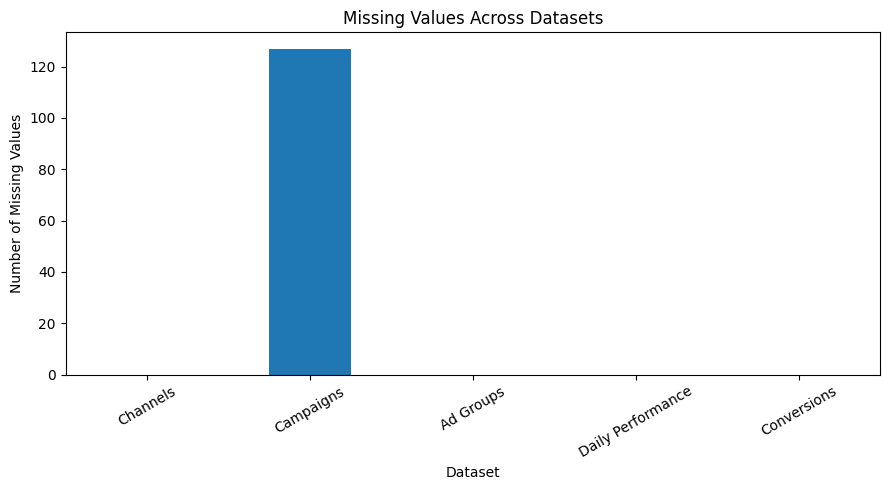

In [ ]:
# Visualizing missing values across datasets
missing_values = quality_report.set_index("Dataset")["Missing Values"]
missing_values.plot(kind="bar", figsize=(9, 5))
plt.title("Missing Values Across Datasets")
plt.xlabel("Dataset")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# Checking columns of all datasets
for name, df in datasets.items():
    print("\n" + "=" * 40)
    print("Dataset:", name)
    print("=" * 40)
    print("Columns:", df.columns.tolist())


Dataset: Channels
Columns: ['channel_id', 'channel_name', 'medium', 'is_paid']

Dataset: Campaigns
Columns: ['campaign_id', 'campaign_name', 'channel_id', 'objective', 'started_on', 'ended_on', 'budget']

Dataset: Ad Groups
Columns: ['ad_group_id', 'campaign_id', 'ad_group_name', 'target_audience', 'status']

Dataset: Daily Performance
Columns: ['performance_id', 'ad_group_id', 'activity_date', 'impressions', 'clicks', 'spend', 'conversions', 'conversion_value']

Dataset: Conversions
Columns: ['conversion_id', 'ad_group_id', 'first_touch_channel_id', 'last_touch_channel_id', 'converted_at', 'revenue', 'touch_count', 'device']


In [ ]:
# Checking ID columns and their uniqueness
for name, df in datasets.items():
    print("\nDataset:", name)
    for col in df.columns:
       if 'id' in col.lower():
            print(
                col,
                "| Unique:", df[col].nunique(),
                "| Total:", df[col].count()
            )


Dataset: Channels
channel_id | Unique: 9 | Total: 9
is_paid | Unique: 2 | Total: 9

Dataset: Campaigns
campaign_id | Unique: 600 | Total: 600
channel_id | Unique: 9 | Total: 600

Dataset: Ad Groups
ad_group_id | Unique: 3000 | Total: 3000
campaign_id | Unique: 516 | Total: 3000

Dataset: Daily Performance
performance_id | Unique: 260000 | Total: 260000
ad_group_id | Unique: 3000 | Total: 260000

Dataset: Conversions
conversion_id | Unique: 40000 | Total: 40000
ad_group_id | Unique: 3000 | Total: 40000
first_touch_channel_id | Unique: 9 | Total: 40000
last_touch_channel_id | Unique: 9 | Total: 40000


In [ ]:
display(quality_report)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Channels,9,4,0,0
1,Campaigns,600,7,127,0
2,Ad Groups,3000,5,0,0
3,Daily Performance,260000,8,0,0
4,Conversions,40000,8,0,0


In [ ]:
for name, df in datasets.items():
    print("\nDataset:", name)
    print("Columns:", df.columns.tolist())
    for col in df.columns:
        if 'id' in col.lower():
            print(col, "| Unique:", df[col].nunique(),
                  "| Total:", df[col].count())


Dataset: Channels
Columns: ['channel_id', 'channel_name', 'medium', 'is_paid']
channel_id | Unique: 9 | Total: 9
is_paid | Unique: 2 | Total: 9

Dataset: Campaigns
Columns: ['campaign_id', 'campaign_name', 'channel_id', 'objective', 'started_on', 'ended_on', 'budget']
campaign_id | Unique: 600 | Total: 600
channel_id | Unique: 9 | Total: 600

Dataset: Ad Groups
Columns: ['ad_group_id', 'campaign_id', 'ad_group_name', 'target_audience', 'status']
ad_group_id | Unique: 3000 | Total: 3000
campaign_id | Unique: 516 | Total: 3000

Dataset: Daily Performance
Columns: ['performance_id', 'ad_group_id', 'activity_date', 'impressions', 'clicks', 'spend', 'conversions', 'conversion_value']
performance_id | Unique: 260000 | Total: 260000
ad_group_id | Unique: 3000 | Total: 260000

Dataset: Conversions
Columns: ['conversion_id', 'ad_group_id', 'first_touch_channel_id', 'last_touch_channel_id', 'converted_at', 'revenue', 'touch_count', 'device']
conversion_id | Unique: 40000 | Total: 40000
ad_group

In [ ]:
for name, df in datasets.items():
    print("\nDataset:", name)
    print(df.dtypes)


Dataset: Channels
channel_id       int32
channel_name    object
medium          object
is_paid           bool
dtype: object

Dataset: Campaigns
campaign_id       int32
campaign_name    object
channel_id        int32
objective        object
started_on       object
ended_on         object
budget           object
dtype: object

Dataset: Ad Groups
ad_group_id         int32
campaign_id         int32
ad_group_name      object
target_audience    object
status             object
dtype: object

Dataset: Daily Performance
performance_id       int32
ad_group_id          int32
activity_date       object
impressions          int32
clicks               int32
spend               object
conversions          int32
conversion_value    object
dtype: object

Dataset: Conversions
conversion_id                      int32
ad_group_id                        int32
first_touch_channel_id             int32
last_touch_channel_id              int32
converted_at              datetime64[us]
revenue                 

In [ ]:
df.dtypes

,0
conversion_id,int32
ad_group_id,int32
first_touch_channel_id,int32
last_touch_channel_id,int32
converted_at,datetime64[us]
revenue,object
touch_count,int32
device,object


In [ ]:
for name, df in datasets.items():
    print("\n---", name, "---")
    print(df.dtypes)


--- Channels ---
channel_id       int32
channel_name    object
medium          object
is_paid           bool
dtype: object

--- Campaigns ---
campaign_id       int32
campaign_name    object
channel_id        int32
objective        object
started_on       object
ended_on         object
budget           object
dtype: object

--- Ad Groups ---
ad_group_id         int32
campaign_id         int32
ad_group_name      object
target_audience    object
status             object
dtype: object

--- Daily Performance ---
performance_id       int32
ad_group_id          int32
activity_date       object
impressions          int32
clicks               int32
spend               object
conversions          int32
conversion_value    object
dtype: object

--- Conversions ---
conversion_id                      int32
ad_group_id                        int32
first_touch_channel_id             int32
last_touch_channel_id              int32
converted_at              datetime64[us]
revenue                      

In [ ]:
# Check date columns
print("CAMPAIGN DATES")
print(campaigns[['started_on', 'ended_on']].head(10))

print("\nDAILY PERFORMANCE DATES")
print(daily_performance['activity_date'].head(10))


CAMPAIGN DATES
   started_on    ended_on
0  2025-07-26        None
1  2024-03-13  2024-09-08
2  2025-10-05  2026-01-11
3  2024-08-06  2024-10-16
4  2025-01-26  2025-11-09
5  2025-04-04  2025-12-07
6  2025-09-13  2025-12-08
7  2025-06-06        None
8  2024-06-04  2024-09-05
9  2024-12-29  2025-03-05

DAILY PERFORMANCE DATES
0    2024-01-09
1    2024-01-10
2    2024-01-11
3    2024-01-12
4    2024-01-13
5    2024-01-13
6    2024-01-14
7    2024-01-14
8    2024-01-14
9    2024-01-15
Name: activity_date, dtype: object


In [ ]:
print("\nCAMPAIGN BUDGET")
print(campaigns['budget'].head(10))
print("\nDAILY SPEND AND CONVERSION VALUE")
print(daily_performance[['spend', 'conversion_value']].head(10))

print("\nCONVERSION REVENUE")
print(conversions['revenue'].head(10))


CAMPAIGN BUDGET
0    81100.00
1    25000.00
2    47700.00
3    54900.00
4    56400.00
5    13400.00
6    17400.00
7     5400.00
8    13400.00
9     9600.00
Name: budget, dtype: object

DAILY SPEND AND CONVERSION VALUE
   spend conversion_value
0   4.99             0.00
1   0.00             0.00
2   1.98             0.00
3   2.17             0.00
4   2.26             0.00
5   7.71             0.00
6  28.94             0.00
7   0.00             0.00
8  31.24             0.00
9  18.16             0.00

CONVERSION REVENUE
0     59.49
1    133.62
2     30.26
3     37.34
4    190.80
5     42.41
6     98.07
7     76.36
8    218.60
9     60.64
Name: revenue, dtype: object


In [ ]:
channels_raw = channels.copy()
campaigns_raw = campaigns.copy()
ad_groups_raw = ad_groups.copy()
daily_performance_raw = daily_performance.copy()
conversions_raw = conversions.copy()
print("Original datasets backed up successfully!")

Original datasets backed up successfully!


In [ ]:
# Convert campaign dates
campaigns['started_on'] = pd.to_datetime(
    campaigns['started_on'], errors='coerce'
)
campaigns['ended_on'] = pd.to_datetime(
    campaigns['ended_on'], errors='coerce'
)
# Convert daily performance date
daily_performance['activity_date'] = pd.to_datetime(
    daily_performance['activity_date'], errors='coerce'
)
# Convert numeric columns
campaigns['budget'] = pd.to_numeric(
    campaigns['budget'], errors='coerce'
)
daily_performance['spend'] = pd.to_numeric(
    daily_performance['spend'], errors='coerce'
)
daily_performance['conversion_value'] = pd.to_numeric(
    daily_performance['conversion_value'], errors='coerce'
)
conversions['revenue'] = pd.to_numeric(
    conversions['revenue'], errors='coerce'
)
print("Data standardization completed!")

Data standardization completed!


In [ ]:
print("Campaigns:")
print(campaigns.dtypes)

print("\nDaily Performance:")
print(daily_performance.dtypes)

print("\nConversions:")
print(conversions.dtypes)

Campaigns:
campaign_id               int32
campaign_name            object
channel_id                int32
objective                object
started_on       datetime64[ns]
ended_on         datetime64[ns]
budget                  float64
dtype: object

Daily Performance:
performance_id               int32
ad_group_id                  int32
activity_date       datetime64[ns]
impressions                  int32
clicks                       int32
spend                      float64
conversions                  int32
conversion_value           float64
dtype: object

Conversions:
conversion_id                      int32
ad_group_id                        int32
first_touch_channel_id             int32
last_touch_channel_id              int32
converted_at              datetime64[us]
revenue                          float64
touch_count                        int32
device                            object
dtype: object


In [ ]:
# Check missing values after standardization
print("CAMPAIGNS")
print(campaigns[['started_on', 'ended_on', 'budget']].isnull().sum())
print("\nDAILY PERFORMANCE")
print(daily_performance[
    ['activity_date', 'spend', 'conversion_value']
].isnull().sum())
print("\nCONVERSIONS")
print(conversions[['revenue']].isnull().sum())

CAMPAIGNS
started_on      0
ended_on      127
budget          0
dtype: int64

DAILY PERFORMANCE
activity_date       0
spend               0
conversion_value    0
dtype: int64

CONVERSIONS
revenue    0
dtype: int64


In [ ]:
print("Campaign Budget:")
print(campaigns['budget'].describe())
print("\nDaily Spend:")
print(daily_performance['spend'].describe())
print("\nConversion Revenue:")
print(conversions['revenue'].describe())

Campaign Budget:
count       600.000000
mean      27132.000000
std       47039.879107
min         100.000000
25%        7975.000000
50%       15000.000000
75%       29550.000000
max      759000.000000
Name: budget, dtype: float64

Daily Spend:
count    260000.000000
mean         12.463843
std          50.898626
min           0.000000
25%           0.000000
50%           0.000000
75%          12.680000
max        4781.330000
Name: spend, dtype: float64

Conversion Revenue:
count    40000.000000
mean        81.892546
std         71.421294
min          3.070000
25%         37.387500
50%         61.820000
75%        102.500000
max       2180.390000
Name: revenue, dtype: float64


In [ ]:
# Connect daily performance with ad groups
analysis_df = daily_performance.merge(
    ad_groups,
    on='ad_group_id',
    how='left'
)
 Connect with campaigns
analysis_df = analysis_df.merge(
    campaigns,
    on='campaign_id',
    how='left'
)
# Connect with channels
analysis_df = analysis_df.merge(
    channels,
    on='channel_id',
    how='left'
)
print("Final Dataset Shape:", analysis_df.shape)
display(analysis_df.head())

Final Dataset Shape: (260000, 21)


,performance_id,ad_group_id,activity_date,impressions,clicks,spend,conversions,conversion_value,campaign_id,ad_group_name,...,status,campaign_name,channel_id,objective,started_on,ended_on,budget,channel_name,medium,is_paid
0,1,2747,2024-01-09,37,2,4.99,0,0.0,112,AG-02747 lookalike,...,active,Black Friday AU,4,traffic,2024-01-02,2024-08-20,36800.0,Video,cpm,True
1,2,2747,2024-01-10,0,0,0.00,0,0.0,112,AG-02747 lookalike,...,active,Black Friday AU,4,traffic,2024-01-02,2024-08-20,36800.0,Video,cpm,True
2,3,2747,2024-01-11,72,4,1.98,0,0.0,112,AG-02747 lookalike,...,active,Black Friday AU,4,traffic,2024-01-02,2024-08-20,36800.0,Video,cpm,True
3,4,2747,2024-01-12,80,3,2.17,0,0.0,112,AG-02747 lookalike,...,active,Black Friday AU,4,traffic,2024-01-02,2024-08-20,36800.0,Video,cpm,True
4,5,2747,2024-01-13,75,3,2.26,0,0.0,112,AG-02747 lookalike,...,active,Black Friday AU,4,traffic,2024-01-02,2024-08-20,36800.0,Video,cpm,True


In [ ]:
# Check unmatched records after merging
print("Total Records:", len(analysis_df))
print("\nMissing Ad Group IDs:")
print(analysis_df['ad_group_id'].isnull().sum())
print("\nMissing Campaign IDs:")
print(analysis_df['campaign_id'].isnull().sum())
print("\nMissing Channel IDs:")
print(analysis_df['channel_id'].isnull().sum())
print("\nMissing Campaign Names:")
print(analysis_df['campaign_name'].isnull().sum())

Total Records: 260000

Missing Ad Group IDs:
0

Missing Campaign IDs:
0

Missing Channel IDs:
0

Missing Campaign Names:
0


In [ ]:
# Calculate campaign-wise performance
kpi_df = analysis_df.groupby(
    'campaign_name'
).agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    spend=('spend', 'sum'),
    conversions=('conversions', 'sum'),
    revenue=('conversion_value', 'sum')
).reset_index()
# Calculate KPIs
kpi_df['CTR (%)'] = (
    kpi_df['clicks'] / kpi_df['impressions'] * 100
)
kpi_df['CPC'] = (
    kpi_df['spend'] / kpi_df['clicks'].replace(0, np.nan)
)
kpi_df['CVR (%)'] = (
    kpi_df['conversions'] /
    kpi_df['clicks'].replace(0, np.nan) * 100
)

kpi_df['CPA'] = (
    kpi_df['spend'] /
    kpi_df['conversions'].replace(0, np.nan)
)
kpi_df['ROAS'] = (
    kpi_df['revenue'] /
    kpi_df['spend'].replace(0, np.nan)
)

display(kpi_df.head(10))

,campaign_name,impressions,clicks,spend,conversions,revenue,CTR (%),CPC,CVR (%),CPA,ROAS
0,Back to School AU,77632,643,932.79,9,599.61,0.828267,1.450684,1.399689,103.643333,0.642813
1,Back to School AU 3,4207,149,0.00,0,0.00,3.541716,0.000000,0.000000,NaN,NaN
2,Back to School AU 4,70815,338,581.15,2,59.71,0.477300,1.719379,0.591716,290.575000,0.102745
3,Back to School AU 5,100272,820,0.00,9,509.53,0.817776,0.000000,1.097561,0.000000,NaN
4,Back to School CA,1420914,7301,11110.92,91,6682.77,0.513824,1.521835,1.246405,122.098022,0.601460
5,Back to School CA 2,179334,1816,2803.88,15,993.27,1.012636,1.543987,0.825991,186.925333,0.354248
6,Back to School CA 3,151309,1052,1398.90,14,738.05,0.695266,1.329753,1.330798,99.921429,0.527593
7,Back to School DE,2320323,11346,17788.47,113,8495.51,0.488984,1.567819,0.995946,157.420088,0.477585
8,Back to School DE 2,57668,723,0.00,5,407.13,1.253728,0.000000,0.691563,0.000000,NaN
9,Back to School DE 3,35370,459,0.00,1,15.97,1.297710,0.000000,0.217865,0.000000,NaN


In [ ]:
channel_analysis = analysis_df.groupby('channel_name').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    spend=('spend', 'sum'),
    conversions=('conversions', 'sum'),
    revenue=('conversion_value', 'sum')
).reset_index()
channel_analysis['CTR (%)'] = (
    channel_analysis['clicks'] /
    channel_analysis['impressions'] * 100
)
channel_analysis['ROAS'] = (
    channel_analysis['revenue'] /
    channel_analysis['spend'].replace(0, np.nan)
)
display(channel_analysis.sort_values(
    'ROAS', ascending=False
))

,channel_name,impressions,clicks,spend,conversions,revenue,CTR (%),ROAS
2,Display,198969054,662411,941503.02,7410,525861.67,0.332922,0.558534
5,Paid Search,48442994,193190,275961.87,2045,152407.12,0.398799,0.552276
0,Affiliate,91617268,369981,534744.24,3901,287157.98,0.403833,0.537001
6,Paid Social,80766614,351989,510973.29,3690,272841.73,0.435810,0.533965
8,Video,116001512,496303,714625.57,5199,378259.08,0.427842,0.529311
7,Retargeting,41095071,183827,262791.19,1866,134706.51,0.447321,0.512599
1,Direct,64956605,292648,0.00,3033,227190.75,0.450528,NaN
3,Email,87006582,365664,0.00,4077,310216.33,0.420272,NaN
4,Organic Search,66785962,298933,0.00,3171,236099.42,0.447599,NaN


In [ ]:
spend_values = analysis_df['spend'].dropna().to_numpy()
revenue_values = analysis_df['conversion_value'].dropna().to_numpy()
print("Average Spend:", np.mean(spend_values))
print("Median Spend:", np.median(spend_values))
print("Spend Standard Deviation:", np.std(spend_values))
print("\nAverage Revenue:", np.mean(revenue_values))
print("Median Revenue:", np.median(revenue_values))
print("Revenue Standard Deviation:", np.std(revenue_values))

Average Spend: 12.463843
Median Spend: 0.0
Spend Standard Deviation: 50.898528394192574

Average Revenue: 9.71054073076923
Median Revenue: 0.0
Revenue Standard Deviation: 72.36336224087538


In [ ]:
# Daily marketing performance
daily_trend = daily_performance.groupby('activity_date').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    spend=('spend', 'sum'),
    revenue=('conversion_value', 'sum')
).reset_index()

# Calculate daily CTR
daily_trend['CTR (%)'] = (
    daily_trend['clicks'] /
    daily_trend['impressions'].replace(0, np.nan) * 100
)
display(daily_trend.head(10))

,activity_date,impressions,clicks,spend,revenue,CTR (%)
0,2024-01-09,37,2,4.99,0.0,5.405405
1,2024-01-10,0,0,0.00,0.0,NaN
2,2024-01-11,72,4,1.98,0.0,5.555556
3,2024-01-12,80,3,2.17,0.0,3.750000
4,2024-01-13,598,10,9.97,0.0,1.672241
5,2024-01-14,1882,25,60.18,0.0,1.328374
6,2024-01-15,2539,22,36.93,0.0,0.866483
7,2024-01-16,1230,13,24.28,0.0,1.056911
8,2024-01-17,6254,50,96.17,0.0,0.799488
9,2024-01-18,9912,72,54.70,48.3,0.726392


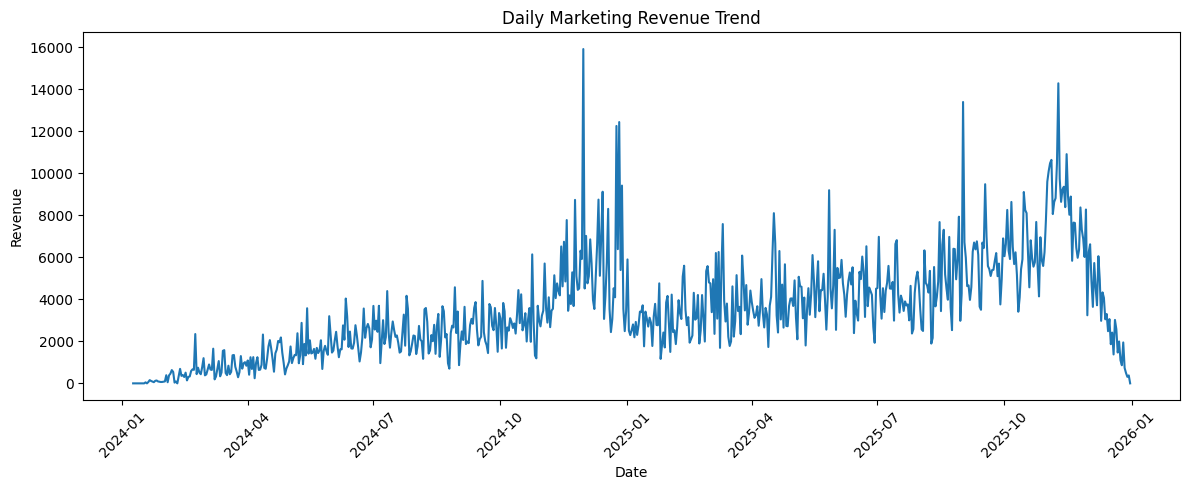

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_trend['activity_date'],
    daily_trend['revenue']
)

plt.title('Daily Marketing Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print("Conversion Dataset Columns:")
print(conversions.columns.tolist())

print("\nSample Conversion Records:")
display(conversions.head(10))

print("\nConversion Data Types:")
print(conversions.dtypes)

Conversion Dataset Columns:
['conversion_id', 'ad_group_id', 'first_touch_channel_id', 'last_touch_channel_id', 'converted_at', 'revenue', 'touch_count', 'device']

Sample Conversion Records:


,conversion_id,ad_group_id,first_touch_channel_id,last_touch_channel_id,converted_at,revenue,touch_count,device
0,1,1972,3,2,2025-02-01 18:54:57,59.49,5,desktop
1,2,1049,7,7,2024-12-20 13:10:19,133.62,2,tablet
2,3,1675,7,7,2024-02-13 17:02:00,30.26,3,mobile
3,4,2624,3,3,2024-01-11 15:21:20,37.34,2,mobile
4,5,1857,6,4,2024-07-16 16:23:06,190.80,4,desktop
5,6,1839,2,7,2025-07-14 18:19:18,42.41,4,desktop
6,7,1009,6,6,2024-09-25 18:09:30,98.07,3,desktop
7,8,850,1,6,2024-03-03 03:02:09,76.36,3,mobile
8,9,58,2,2,2024-11-23 16:10:21,218.60,2,desktop
9,10,1141,1,2,2025-12-07 17:07:55,60.64,1,mobile



Conversion Data Types:
conversion_id                      int32
ad_group_id                        int32
first_touch_channel_id             int32
last_touch_channel_id              int32
converted_at              datetime64[us]
revenue                          float64
touch_count                        int32
device                            object
dtype: object


In [ ]:
print(conversions.columns.tolist())
display(conversions.head(5))

['conversion_id', 'ad_group_id', 'first_touch_channel_id', 'last_touch_channel_id', 'converted_at', 'revenue', 'touch_count', 'device']


,conversion_id,ad_group_id,first_touch_channel_id,last_touch_channel_id,converted_at,revenue,touch_count,device
0,1,1972,3,2,2025-02-01 18:54:57,59.49,5,desktop
1,2,1049,7,7,2024-12-20 13:10:19,133.62,2,tablet
2,3,1675,7,7,2024-02-13 17:02:00,30.26,3,mobile
3,4,2624,3,3,2024-01-11 15:21:20,37.34,2,mobile
4,5,1857,6,4,2024-07-16 16:23:06,190.80,4,desktop


In [ ]:
print(conversions[['ad_group_id', 'converted_at', 'revenue']].head())

   ad_group_id        converted_at  revenue
0         1972 2025-02-01 18:54:57    59.49
1         1049 2024-12-20 13:10:19   133.62
2         1675 2024-02-13 17:02:00    30.26
3         2624 2024-01-11 15:21:20    37.34
4         1857 2024-07-16 16:23:06   190.80


In [ ]:
attribution_summary = conversions.groupby('ad_group_id').agg(
    total_conversions=('ad_group_id', 'count'),
    total_revenue=('revenue', 'sum')
).reset_index()

attribution_summary = attribution_summary.sort_values(
    'total_revenue', ascending=False
)

display(attribution_summary.head(10))

,ad_group_id,total_conversions,total_revenue
298,299,13,3215.25
2,3,14,2530.15
725,726,13,2443.53
1058,1059,14,2419.93
480,481,13,2303.23
1928,1929,13,2239.36
2433,2434,14,2220.92
957,958,13,2210.27
849,850,14,2146.48
1787,1788,13,2116.80


In [ ]:
# Create a budget reallocation scenario

budget_scenario = channel_analysis.copy()

total_budget = budget_scenario['spend'].sum()

# Calculate each channel's share of total ROAS
total_roas = budget_scenario['ROAS'].clip(lower=0).sum()

if total_roas > 0:
    budget_scenario['Proposed Budget'] = (
        total_budget *
        budget_scenario['ROAS'].clip(lower=0) / total_roas
    )
else:
    print("ROAS values are not suitable for budget allocation.")

budget_scenario['Current Budget'] = budget_scenario['spend']

if total_roas > 0:
    budget_scenario['Budget Change'] = (
        budget_scenario['Proposed Budget'] -
        budget_scenario['Current Budget']
    )

    display(budget_scenario[
        ['channel_name', 'Current Budget',
         'Proposed Budget', 'Budget Change', 'ROAS']
    ].round(2))

,channel_name,Current Budget,Proposed Budget,Budget Change,ROAS
0,Affiliate,534744.24,539818.08,5073.84,0.54
1,Direct,0.00,NaN,NaN,NaN
2,Display,941503.02,561464.69,-380038.33,0.56
3,Email,0.00,NaN,NaN,NaN
4,Organic Search,0.00,NaN,NaN,NaN
5,Paid Search,275961.87,555173.63,279211.76,0.55
6,Paid Social,510973.29,536766.31,25793.02,0.53
7,Retargeting,262791.19,515288.48,252497.29,0.51
8,Video,714625.57,532088.00,-182537.57,0.53


In [ ]:
# Identify the best performing channel

best_roas = channel_analysis.loc[
    channel_analysis['ROAS'].idxmax()
]

best_ctr = channel_analysis.loc[
    channel_analysis['CTR (%)'].idxmax()
]

print("Best ROAS Channel:", best_roas['channel_name'])
print("Highest ROAS:", round(best_roas['ROAS'], 2))

print("\nBest CTR Channel:", best_ctr['channel_name'])
print("Highest CTR:", round(best_ctr['CTR (%)'], 2))

print("\nTotal Marketing Spend:",
      round(channel_analysis['spend'].sum(), 2))

print("Total Revenue:",
      round(channel_analysis['revenue'].sum(), 2))

Best ROAS Channel: Display
Highest ROAS: 0.56

Best CTR Channel: Direct
Highest CTR: 0.45

Total Marketing Spend: 3240599.18
Total Revenue: 2524740.59


## Limitations of the Analysis

1. The dataset may not represent real-world marketing behaviour.
2. Attribution analysis is limited by the availability of customer journey and touchpoint data.
3. Last-touch attribution may ignore the influence of earlier marketing interactions.
4. The budget reallocation scenario is hypothetical and does not guarantee improved performance.
5. Historical campaign performance may not predict future results.
6. External factors such as seasonality, competition and audience behaviour may affect campaign performance.

## Conclusion

This project analysed marketing campaign performance using Python, Pandas and NumPy. Multiple datasets were explored, cleaned, standardized and combined to study campaign and channel performance.

Key performance indicators such as CTR, CPC, CVR, CPA and ROAS were used to evaluate marketing efficiency. Statistical analysis and visualizations helped identify performance patterns.

A hypothetical budget reallocation scenario was also developed using channel ROAS. The analysis highlights the importance of data quality, attribution methods and evidence-based budget decisions.